# 3. Monotone fits and the pool-adjacent-violators algorithm

The pressure of a stable fluid cannot rise with its volume at constant temperature, and a curve fitted to noisy data does not know this. The pool-adjacent-violators algorithm (PAVA) finds the monotone sequence closest to the data in one pass. Applied to a van der Waals isotherm below the critical temperature, it reproduces Maxwell's equal-area construction.

## Learning objectives

1. Relate the convexity of the Helmholtz energy in the volume to a pressure that does not rise with the volume.
2. Follow the pool-adjacent-violators algorithm (`linear_physics.pava_monotone_regression`) on four points by hand.
3. Compare the monotone fit with unconstrained polynomials on a noisy synthetic isotherm.
4. Apply the algorithm to a van der Waals isotherm below the critical temperature and compare the plateau with Maxwell's equal-area rule.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
For a single-phase pure fluid at constant temperature $T$, the differential of molar Helmholtz free energy is $dA_m = -S_m\,dT - P\,dV_m$, so $P = -\left(\frac{\partial A_m}{\partial V_m}\right)_T$. **Second-law mechanical stability** requires $A_m(V_m)$ to be locally convex ($\partial^2 A_m / \partial V_m^2 \ge 0$), which demands non-negative isothermal compressibility $\kappa_T > 0$ and a monotonically non-increasing pressure isotherm:
$$\left(\frac{\partial P}{\partial V_m}\right)_T = -\left(\frac{\partial^2 A_m}{\partial V_m^2}\right)_T \le 0, \qquad \kappa_T = -\frac{1}{V_m}\left(\frac{\partial V_m}{\partial P}\right)_T \ge 0 \tag{1.1}$$
Given $N$ noisy measurements $\mathbf{y} \in \mathbb{R}^N$ ordered along $V_{m,1} < V_{m,2} < \dots < V_{m,N}$, **isotonic regression** computes the orthogonal $L_2$ projection onto the closed convex monotone cone $\mathcal{C}_{\downarrow} = \{\mathbf{f} \in \mathbb{R}^N : f_1 \ge f_2 \ge \dots \ge f_N\}$:
$$\hat{\mathbf{f}}_{\mathrm{PAVA}} = \Pi_{\mathcal{C}_{\downarrow}}(\mathbf{y}) = \arg\min_{\mathbf{f} \in \mathcal{C}_{\downarrow}} \frac{1}{2}\|\mathbf{f} - \mathbf{y}\|_2^2 \tag{1.2}$$
By Moreau's convex cone projection theorem, the **pool-adjacent-violators algorithm (PAVA, ayer et al. 1955)** finds the exact global minimum in $O(N)$ time and satisfies two fundamental identities for any true monotone curve $\mathbf{f}_{\mathrm{true}} \in \mathcal{C}_{\downarrow}$:
$$\sum_{i=1}^N \hat{f}_{\mathrm{PAVA},i} = \sum_{i=1}^N y_i \quad (\text{mean conservation}), \qquad \|\hat{\mathbf{f}}_{\mathrm{PAVA}} - \mathbf{f}_{\mathrm{true}}\|_2 \le \|\mathbf{y} - \mathbf{f}_{\mathrm{true}}\|_2 \quad (L_2\text{ Contraction}) \tag{1.3}$$

In [2]:
heading("Demonstration 1: 4-Point Pen-and-Paper PAVA Walkthrough and a noisy synthetic isotherm")
y_micro = np.array([1.0, 3.0, 2.0, 4.5])
f_micro = linear_physics.pava_monotone_regression(y_micro, increasing=True)
print("4-Point Micro-Example Input y :", y_micro)
print("4-Point PAVA Increasing Output:", f_micro, "(Adjacent violators [3.0, 2.0] pooled to mean 2.5)")
assert np.allclose(f_micro, [1.0, 2.5, 2.5, 4.5], atol=1e-15)

# A synthetic isotherm of cubic-equation-of-state form with assumed constants (V_m in L/mol, P in MPa):
rng = np.random.default_rng(42)
Vm = np.linspace(0.12, 0.80, 40)
P_true = 33.2 / (Vm - 0.065) - 9.4 / (Vm ** 2 + 0.13 * Vm)
P_noisy = P_true + rng.normal(0.0, 2.2, size=len(Vm))
P_pava = linear_physics.pava_monotone_regression(P_noisy, increasing=False)

assert float(np.max(np.diff(P_pava))) <= 1e-15, "PAVA isotherm must satisfy dP/dVm <= 0 everywhere!"
assert np.isclose(np.mean(P_pava), np.mean(P_noisy), rtol=1e-14), "PAVA must conserve the sample mean!"
print(f"Noisy isotherm stability violations (dP > 0): {int(np.sum(np.diff(P_noisy) > 0))} intervals")
print(f"PAVA isotherm stability violations  (dP > 0): {int(np.sum(np.diff(P_pava) > 0))} intervals")


Demonstration 1: 4-Point Pen-and-Paper PAVA Walkthrough and a noisy synthetic isotherm
4-Point Micro-Example Input y : [1.  3.  2.  4.5]
4-Point PAVA Increasing Output: [1.  2.5 2.5 4.5] (Adjacent violators [3.0, 2.0] pooled to mean 2.5)
Noisy isotherm stability violations (dP > 0): 9 intervals
PAVA isotherm stability violations  (dP > 0): 0 intervals


**What Demonstration 1 shows.** Where noise makes the pressure rise with the volume ($P_{i+1} > P_i$ at $V_{m,i+1} > V_{m,i}$), the algorithm replaces the offending neighbours by their mean, and repeats until no violation is left. The synthetic isotherm has 9 such intervals before and none after, and the mean of the data is unchanged.

---

## 2. Numerical walkthrough
Let us inspect the block-pooling structure of PAVA on the first 8 molar-volume points of the isotherm, showing each pooled plateau's block size $n_b$, block sum $S_b$, and constant plateau pressure $\bar{P}_b = S_b / n_b$.

In [3]:
heading("Demonstration 2: Step-by-Step Stack Block-Pooling Inspection")
y_sub8 = P_noisy[:8]
blocks = []
for idx, val in enumerate(y_sub8):
    blocks.append([float(val), 1])
    while len(blocks) >= 2 and (blocks[-2][0] / blocks[-2][1]) < (blocks[-1][0] / blocks[-1][1]):  # decreasing check
        last = blocks.pop()
        blocks[-1][0] += last[0]
        blocks[-1][1] += last[1]
    plateaus = [round(b[0] / b[1], 2) for b in blocks]
    counts = [b[1] for b in blocks]
    print(f"Step {idx+1} (insert P={val:6.2f} MPa) -> Active blocks (mean, count): {list(zip(plateaus, counts))}")


Demonstration 2: Step-by-Step Stack Block-Pooling Inspection
Step 1 (insert P=290.97 MPa) -> Active blocks (mean, count): [(290.97, 1)]
Step 2 (insert P=200.30 MPa) -> Active blocks (mean, count): [(290.97, 1), (200.3, 1)]
Step 3 (insert P=158.00 MPa) -> Active blocks (mean, count): [(290.97, 1), (200.3, 1), (158.0, 1)]
Step 4 (insert P=131.00 MPa) -> Active blocks (mean, count): [(290.97, 1), (200.3, 1), (158.0, 1), (131.0, 1)]
Step 5 (insert P=106.92 MPa) -> Active blocks (mean, count): [(290.97, 1), (200.3, 1), (158.0, 1), (131.0, 1), (106.92, 1)]
Step 6 (insert P= 96.08 MPa) -> Active blocks (mean, count): [(290.97, 1), (200.3, 1), (158.0, 1), (131.0, 1), (106.92, 1), (96.08, 1)]
Step 7 (insert P= 90.27 MPa) -> Active blocks (mean, count): [(290.97, 1), (200.3, 1), (158.0, 1), (131.0, 1), (106.92, 1), (96.08, 1), (90.27, 1)]
Step 8 (insert P= 82.44 MPa) -> Active blocks (mean, count): [(290.97, 1), (200.3, 1), (158.0, 1), (131.0, 1), (106.92, 1), (96.08, 1), (90.27, 1), (82.44, 1)

**What Demonstration 2 shows.** Each point enters the stack once, and each merge removes one block, so the inner `while` loop runs at most $N - 1$ times over the whole data set: the cost is proportional to $N$.

---

## 3. Worked case study
Let us compare our non-parametric $O(N)$ PAVA projection against an unconstrained degree-7 polynomial fit `np.polyfit(Vm, P_noisy, deg=7)` on the 40 points of the isotherm.

In [4]:
heading("Demonstration 3: PAVA vs. Unconstrained Degree-7 Polynomial Benchmark")
poly_coef = np.polyfit(Vm, P_noisy, deg=7)
P_poly7 = np.polyval(poly_coef, Vm)
poly_violations = int(np.sum(np.diff(P_poly7) > 0))

rmse_noisy = float(np.sqrt(np.mean((P_noisy - P_true) ** 2)))
rmse_poly7 = float(np.sqrt(np.mean((P_poly7 - P_true) ** 2)))
rmse_pava = float(np.sqrt(np.mean((P_pava - P_true) ** 2)))
print(f"RMSE vs True Isotherm: Noisy = {rmse_noisy:.3f} MPa | Poly-7 = {rmse_poly7:.3f} MPa ({poly_violations} violations) | PAVA = {rmse_pava:.3f} MPa (0 violations)")
assert rmse_pava < rmse_noisy and poly_violations > 0


Demonstration 3: PAVA vs. Unconstrained Degree-7 Polynomial Benchmark
RMSE vs True Isotherm: Noisy = 1.796 MPa | Poly-7 = 2.574 MPa (2 violations) | PAVA = 1.466 MPa (0 violations)


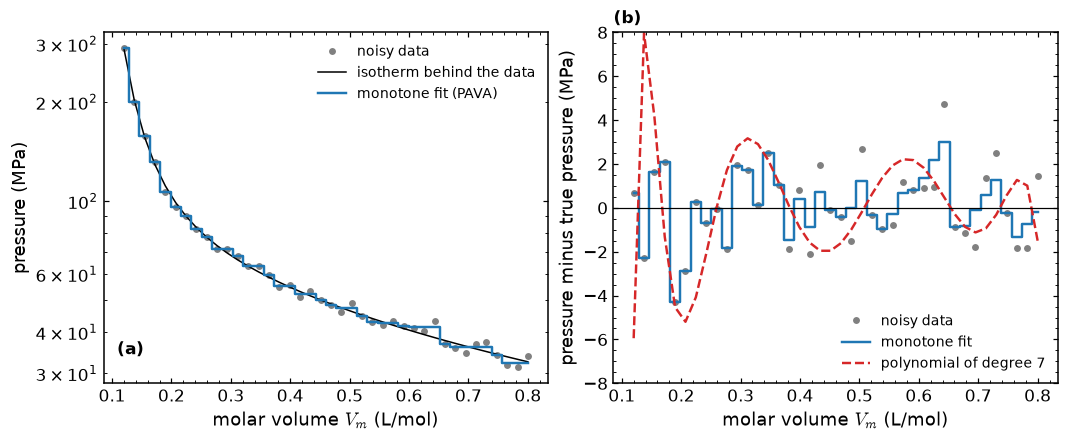

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.plot(Vm, P_noisy, "o", ms=3.5, color="0.5", label="noisy data")
ax1.plot(Vm, P_true, "-", color="k", lw=1.0, label="isotherm behind the data")
ax1.step(Vm, P_pava, where="mid", color="C0", label="monotone fit (PAVA)")
ax1.set_yscale("log"); ax1.set_xlabel(r"molar volume $V_m$ (L/mol)"); ax1.set_ylabel("pressure (MPa)")
ax1.legend(fontsize=9); panel_label(ax1, "(a)", x=0.03, y=0.12)
ax2.plot(Vm, P_noisy - P_true, "o", ms=3.5, color="0.5", label="noisy data")
ax2.step(Vm, P_pava - P_true, where="mid", color="C0", label="monotone fit")
ax2.plot(Vm, P_poly7 - P_true, "--", color="C3", label="polynomial of degree 7")
ax2.axhline(0.0, color="k", lw=0.8); ax2.set_ylim(-8.0, 8.0)
ax2.set_xlabel(r"molar volume $V_m$ (L/mol)"); ax2.set_ylabel("pressure minus true pressure (MPa)")
ax2.legend(fontsize=9, loc="lower right"); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 3.1.** A synthetic isotherm with noise. (a) The data, the isotherm that generated them and the monotone fit, which is a staircase: wherever the data rise, neighbours are pooled into a step. (b) The deviations from the true isotherm. The polynomial of degree 7 cannot follow the steep rise at small volumes and oscillates (part of its curve is outside the range shown).

**What Demonstration 3 shows.** Against the isotherm that generated the data, the error of the noisy points is $1.80\;\mathrm{MPa}$. The monotone fit reduces it to $1.47\;\mathrm{MPa}$, by $18\ \%$, with no violation. The unconstrained polynomial of degree 7 is worse than the raw data ($2.57\;\mathrm{MPa}$) and still has two intervals where the pressure rises with the volume.

---

## 4. What if: sensitivity to the parameters
What happens when the algorithm is applied to an isotherm of the van der Waals equation below the critical temperature, which contains a loop ($(\partial P / \partial V_m)_T > 0$)?

In [6]:
heading("Demonstration 4: The van der Waals loop and the equal-area plateau")
# Reduced van der Waals isotherm at T_r = 0.9:  P_r = 8 T_r / (3 V_r - 1) - 3 / V_r^2
T_r = 0.9
Vm_sub = np.linspace(0.45, 5.0, 1821)                      # reduced volume, uniform grid
P_vdw = 8.0 * T_r / (3.0 * Vm_sub - 1.0) - 3.0 / Vm_sub ** 2
P_maxwell_pava = linear_physics.pava_monotone_regression(P_vdw, increasing=False)
n_spinodal = int(np.sum(np.diff(P_vdw) > 0))
n_after = int(np.sum(np.diff(P_maxwell_pava) > 0))
plateau_vals, plateau_counts = np.unique(np.round(P_maxwell_pava, 9), return_counts=True)
p_sat_est = plateau_vals[int(np.argmax(plateau_counts))]

# Independent check: Maxwell's equal-area rule, solved by bisection on the saturation pressure.
def equal_area_mismatch(p_sat):
    """Integral of (P - p_sat) dV between the outer roots of P(V) = p_sat; zero at saturation."""
    roots = np.roots([3.0 * p_sat, -(p_sat + 8.0 * T_r), 9.0, -3.0])       # cubic in V_r
    v_l, v_g = np.min(roots.real), np.max(roots.real)
    antiderivative = lambda v: (8.0 * T_r / 3.0) * np.log(3.0 * v - 1.0) + 3.0 / v
    return antiderivative(v_g) - antiderivative(v_l) - p_sat * (v_g - v_l), v_l, v_g

p_lo, p_hi = 0.45, 0.72                                     # between the two spinodal pressures
for _ in range(60):
    p_mid = 0.5 * (p_lo + p_hi)
    if equal_area_mismatch(p_mid)[0] > 0.0:
        p_lo = p_mid
    else:
        p_hi = p_mid
p_sat_maxwell, v_liq, v_gas = p_mid, *equal_area_mismatch(p_mid)[1:]
on_plateau = np.isclose(P_maxwell_pava, p_sat_est, atol=1e-8)
print(f"Intervals where the pressure rises with the volume: {n_spinodal} -> after PAVA: {n_after}")
print(f"Plateau of the monotone fit    : P_r = {p_sat_est:.5f}, from V_r = {Vm_sub[on_plateau][0]:.3f} to {Vm_sub[on_plateau][-1]:.3f} ({np.max(plateau_counts)} grid points)")
print(f"Maxwell's equal-area rule      : P_r = {p_sat_maxwell:.5f}, from V_r = {v_liq:.3f} to {v_gas:.3f}")
assert n_spinodal > 10 and n_after == 0
assert np.isclose(np.mean(P_maxwell_pava), np.mean(P_vdw), rtol=1e-12)
assert abs(p_sat_est - p_sat_maxwell) < 2e-3


Demonstration 4: The van der Waals loop and the equal-area plateau
Intervals where the pressure rises with the volume: 324 -> after PAVA: 0
Plateau of the monotone fit    : P_r = 0.64700, from V_r = 0.605 to 2.348 (698 grid points)
Maxwell's equal-area rule      : P_r = 0.64700, from V_r = 0.603 to 2.349


area above the plateau = 0.06175; area below = 0.06175


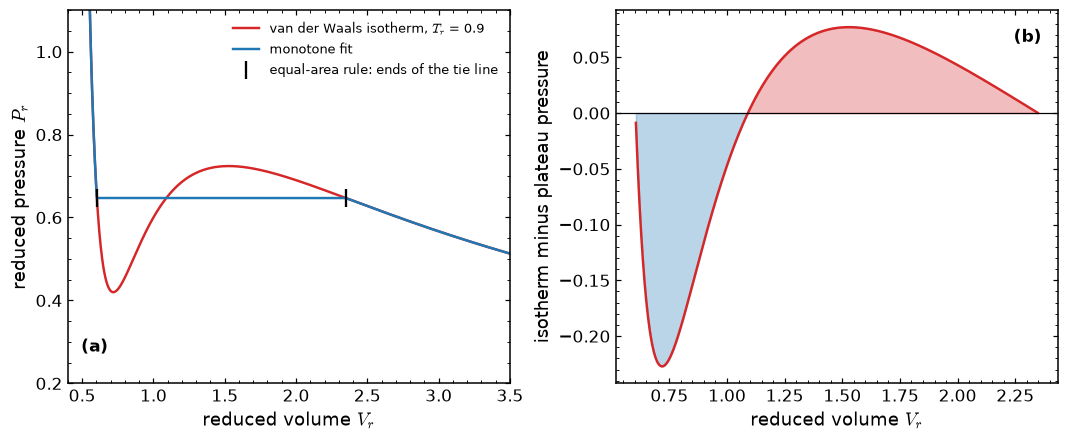

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.plot(Vm_sub, P_vdw, "-", color="C3", label="van der Waals isotherm, $T_r$ = 0.9")
ax1.plot(Vm_sub, P_maxwell_pava, "-", color="C0", label="monotone fit")
ax1.plot([v_liq, v_gas], [p_sat_maxwell, p_sat_maxwell], "k|", ms=12, mew=1.5, label="equal-area rule: ends of the tie line")
ax1.set_xlim(0.4, 3.5); ax1.set_ylim(0.2, 1.1)
ax1.set_xlabel(r"reduced volume $V_r$"); ax1.set_ylabel(r"reduced pressure $P_r$")
ax1.legend(fontsize=8.5, loc="upper right"); panel_label(ax1, "(a)", x=0.03, y=0.12)
ax2.plot(Vm_sub[on_plateau], P_vdw[on_plateau] - p_sat_est, "-", color="C3")
ax2.fill_between(Vm_sub[on_plateau], P_vdw[on_plateau] - p_sat_est, 0.0, where=P_vdw[on_plateau] > p_sat_est, color="C3", alpha=0.3)
ax2.fill_between(Vm_sub[on_plateau], P_vdw[on_plateau] - p_sat_est, 0.0, where=P_vdw[on_plateau] < p_sat_est, color="C0", alpha=0.3)
ax2.axhline(0.0, color="k", lw=0.8)
ax2.set_xlabel(r"reduced volume $V_r$"); ax2.set_ylabel("isotherm minus plateau pressure"); panel_label(ax2, "(b)", x=0.9)
dV = Vm_sub[1] - Vm_sub[0]
print(f"area above the plateau = {np.sum(np.clip(P_vdw[on_plateau] - p_sat_est, 0, None)) * dV:.5f}; area below = {np.sum(np.clip(p_sat_est - P_vdw[on_plateau], 0, None)) * dV:.5f}")
plt.show()

**Figure 3.2.** (a) The reduced van der Waals isotherm at $T_r = 0.9$ and its monotone fit, which replaces the loop by a plateau. The two marks are the ends of the tie line from Maxwell's equal-area rule, computed independently. (b) The isotherm minus the plateau pressure over the pooled points: the two shaded areas are equal.

**What Demonstration 4 shows.** Below the critical temperature the van der Waals isotherm has a loop in which the pressure rises with the volume. The monotone fit replaces the loop and parts of its two flanks by one plateau at $P_r = 0.64700$, between $V_r = 0.605$ and $2.348$. Maxwell's equal-area rule, solved independently by bisection, gives $P_r = 0.64700$ between $V_r = 0.603$ and $2.349$. The agreement is not a coincidence: on a uniform grid in volume the plateau is the mean of the pressures it replaces, so the areas between the isotherm and the plateau cancel, and the plateau ends where the isotherm returns to the plateau pressure. These are the two conditions of the equal-area rule, and the small differences in the end points are the spacing of the grid.

---

## Inside the algorithm
Below we run a standalone 12-line stack-based PAVA implementation in pure NumPy and verify digit-for-digit agreement with `linear_physics.pava_monotone_regression`.

In [8]:
heading("Inside the Algorithm: By-Hand Stack PAVA vs. the Library")
def pava_increasing_by_hand(y_arr: np.ndarray) -> np.ndarray:
    st: list[list[float]] = []
    for v in y_arr:
        st.append([float(v), 1.0])
        while len(st) >= 2 and st[-2][0] / st[-2][1] > st[-1][0] / st[-1][1]:
            s_r, c_r = st.pop()
            st[-1][0] += s_r
            st[-1][1] += c_r
    return np.concatenate([np.full(int(c), s / c) for s, c in st])

p_hand = -pava_increasing_by_hand(-P_noisy)
diff_pava = float(np.max(np.abs(p_hand - P_pava)))
print("by hand (pure NumPy) first 6 pts:", np.round(p_hand[:6], 5))
print("library (engml_2_applied)      first 6 pts:", np.round(P_pava[:6], 5))
print(f"Max digit-for-digit discrepancy : {diff_pava:.2e}")
assert diff_pava < 1e-15


Inside the Algorithm: By-Hand Stack PAVA vs. the Library
by hand (pure NumPy) first 6 pts: [290.97341 200.30284 158.00408 131.00282 106.91532  96.08164]
library (engml_2_applied)      first 6 pts: [290.97341 200.30284 158.00408 131.00282 106.91532  96.08164]
Max digit-for-digit discrepancy : 0.00e+00


## Exercises

1. **Verify a result.** Generate $N = 50$ noisy Langmuir $\mathrm{CO_2}$ adsorption uptake measurements $q(P) = q_{\max} K P / (1 + K P)$ of Langmuir form with assumed constants ($q_{\max} = 5.2\;\mathrm{mol/kg}, K = 1.4\;\mathrm{bar}^{-1}$) across $P \in [0.1, 10.0]\;\mathrm{bar}$ with Gaussian noise $\sigma = 0.25\;\mathrm{mol/kg}$. Apply `pava_monotone_regression(.., increasing=True)` and verify that (1) $\min(\Delta \hat{q}) \ge 0$, (2) $\mathrm{mean}(\hat{q}) = \mathrm{mean}(y)$, and (3) $\|\hat{\mathbf{q}}_{\mathrm{PAVA}} - \mathbf{q}_{\mathrm{true}}\|_2 < \|\mathbf{y} - \mathbf{q}_{\mathrm{true}}\|_2$.
2. **Find how it fails.** Show why Newton's method for the inverse problem $P(V_m) = P_{\mathrm{target}}$ fails on a staircase: for the pooled van der Waals isotherm of Demonstration 4 (`P_maxwell_pava` on the grid `Vm_sub`), compute the finite-difference slope $\Delta \hat{P}/\Delta V_m$ on every interval and report the fraction of intervals where it is zero.
3. **Write it yourself.** Implement a **weighted PAVA** function `weighted_pava_increasing(y: np.ndarray, weights: np.ndarray) -> np.ndarray` that minimizes $\sum_{i=1}^N w_i (f_i - y_i)^2$ subject to $f_1 \le \dots \le f_N$ by accumulating `[weighted_sum, total_weight]` in each stack block. Verify that it conserves the weighted mean $\sum_i w_i \hat{f}_i = \sum_i w_i y_i$ and matches `pava_monotone_regression` when $w_i \equiv 1$.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: PAVA Projection of a Synthetic CO2 Adsorption Isotherm")
rng_ex = np.random.default_rng(77)
P_ads = np.linspace(0.1, 10.0, 50)
q_true = 5.2 * 1.4 * P_ads / (1.0 + 1.4 * P_ads)
q_noisy = q_true + rng_ex.normal(0.0, 0.25, size=50)
q_pava = linear_physics.pava_monotone_regression(q_noisy, increasing=True)

assert float(np.min(np.diff(q_pava))) >= -1e-15
assert np.isclose(np.mean(q_pava), np.mean(q_noisy), rtol=1e-14)
assert np.linalg.norm(q_pava - q_true) < np.linalg.norm(q_noisy - q_true)
print(f"Synthetic adsorption isotherm, L2 error: Raw = {np.linalg.norm(q_noisy - q_true):.3f} -> PAVA = {np.linalg.norm(q_pava - q_true):.3f} mol/kg")


Exercise 1: PAVA Projection of a Synthetic CO2 Adsorption Isotherm
Synthetic adsorption isotherm, L2 error: Raw = 1.866 -> PAVA = 0.820 mol/kg
